# 02 · Reporting areas by region, ecoregion and hexagon

**Question:** the platform reports forest and loss for each region (ADM1), prefecture (ADM2) and H3 hexagon. Do the 100 m shares give each unit the area of its 30 m pixels? And how far off are the products that count the half-cell masks instead?

What the platform reports, and from what (origin/main, 2026-10-26):

| Product | Units | Counts |
|---|---|---|
| National summary, zonal statistics (forest, loss per year, rates) | Guinea, ADM1, ADM2 | The shares (`forest_share_by_year`, `loss_by_year`) |
| Forest-cover layer and its hexagons (`forest-cover-h3`) | H3 resolutions 7 to 4 | The half-cell masks (`forest_by_year`) |
| Risk per hexagon (`risk-h3`), prefecture risk summary | H3, ADM2 | Forest from the half-cell mask (`forest_now`) |
| Baseline projection | Guinea | Forest from the half-cell mask of the last year |

How each is counted here:

* **Shares:** each 100 m cell goes wholly to the unit holding its centre, as the platform's `rasterize` does, with its share of forest and of each year's loss times its area.
* **Half-cell masks:** a cell is forest while at least half of it is, and lost in the year it falls below half (`HansenShares.display_arrays`).
* **30 m pixels (the reference):** Hansen's 30 m tiles of the same release, each pixel going to the unit holding its centre, with the definitions of the shares and the platform's area formula.

Hexagons: the platform computes resolution 7 (about 5 km²) and sums children for 6, 5 and 4 (about 36, 253 and 1,770 km²). Hexagons are compared only when wholly inside Guinea. Errors are the median and 95th percentile of the error in % of the 30 m figure, over units with at least 10 ha of it. "Misplaced" is the sum of the absolute errors as a share of the total. The code is `scripts/reporting.py`.

The 30 m tiles come from Hansen's public download, not from Earth Engine. The Earth Engine quota of the account used here was used up for October (restricted mode until 1 November).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
sys.path.insert(0, str(HERE.parent / "scripts"))
import reporting as R

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
OUT = HERE.parent / "outputs" / "summary"
levels = R.unit_tables()
ORDER = ["H3 res 7", "H3 res 6", "H3 res 5", "ADM2", "H3 res 4", "ADM1", "ecoregion", "ADM0"]
NAMES = {"ADM0": "Guinea", "ADM1": "Region (ADM1)", "ADM2": "Prefecture (ADM2)", "ecoregion": "Ecoregion"}
FIGURES = ["Forest 2000", "Forest 2024", "Loss 2001–2024", "Loss 2022–2024", "Loss, single years (mean)"]

## 1 · The shares against the 30 m pixels

In [2]:
rows = []
for level in ORDER:
    shares, masks, truth = levels[level]
    for method, estimate in (("Shares", shares), ("Half-cell masks", masks)):
        e = R.errors(estimate, truth)
        for figure in FIGURES:
            rows.append({"Level": NAMES.get(level, level), "Units": len(truth), "Method": method, "Figure": figure,
                         "Mean unit (km²)": truth["Land"].mean() / 100, **e.loc[figure]})
err = pd.DataFrame(rows)
err.round(3).to_csv(OUT / "02_errors.csv", index=False)
view = lambda method, value: err[err.Method == method].pivot(index="Level", columns="Figure", values=value).loc[
    [NAMES.get(l, l) for l in ORDER], FIGURES]
print("Shares: median |error| (% of the 30 m figure)")
display(view("Shares", "Median |error| (%)").round(2))
print("Shares: 95th percentile |error| (%)")
display(view("Shares", "95th pct |error| (%)").round(2))
print("Shares: misplaced (% of the total)")
view("Shares", "Misplaced (% of total)").round(2)

Shares: median |error| (% of the 30 m figure)


Figure,Forest 2000,Forest 2024,Loss 2001–2024,Loss 2022–2024,"Loss, single years (mean)"
Level,,,,,
H3 res 7,0.69,0.75,0.89,1.16,1.06
H3 res 6,0.16,0.18,0.26,0.44,0.55
H3 res 5,0.04,0.05,0.08,0.13,0.25
Prefecture (ADM2),0.01,0.01,0.01,0.01,0.05
H3 res 4,0.01,0.01,0.03,0.03,0.11
Region (ADM1),0.00,0.00,0.00,0.01,0.03
Ecoregion,0.00,0.00,0.00,0.00,0.03
Guinea,0.01,0.01,0.00,0.00,0.02


Shares: 95th percentile |error| (%)


Figure,Forest 2000,Forest 2024,Loss 2001–2024,Loss 2022–2024,"Loss, single years (mean)"
Level,,,,,
H3 res 7,2.54,2.69,3.68,4.69,4.85
H3 res 6,0.89,0.98,1.32,2.07,2.68
H3 res 5,0.31,0.34,0.45,0.63,1.30
Prefecture (ADM2),0.09,0.14,0.10,0.09,0.33
H3 res 4,0.11,0.08,0.27,0.24,0.54
Region (ADM1),0.11,0.12,0.47,0.99,0.11
Ecoregion,0.19,0.26,0.01,0.01,0.12
Guinea,0.01,0.01,0.00,0.00,0.02


Shares: misplaced (% of the total)


Figure,Forest 2000,Forest 2024,Loss 2001–2024,Loss 2022–2024,"Loss, single years (mean)"
Level,,,,,
H3 res 7,0.73,0.80,0.95,1.74,2.87
H3 res 6,0.16,0.18,0.24,0.49,1.00
H3 res 5,0.04,0.04,0.06,0.13,0.32
Prefecture (ADM2),0.01,0.01,0.01,0.01,0.04
H3 res 4,0.01,0.01,0.02,0.03,0.11
Region (ADM1),0.01,0.01,0.01,0.01,0.02
Ecoregion,0.01,0.01,0.00,0.00,0.03
Guinea,0.01,0.01,0.00,0.00,0.02


**Reading:**

* **For Guinea, every region, prefecture and ecoregion, the shares give the 30 m figures:** median error 0.01 % or less, and under 1 % for every unit and figure, single years included.
* **Hexagons are less exact the smaller they are,** because only the cells along their edges go to the wrong side.
  * **Resolution 7 (about 5 km²):** median error 0.7–1.2 %; 95th percentile 2.5–4.9 %.
  * **Resolution 6 (about 36 km²):** median under 0.6 %; 95th percentile under 2.7 %.
  * **Resolutions 5 and 4:** median under 0.3 %; 95th percentile under 1.3 %.
* **The errors have no direction:** they cancel when hexagons are summed (bias 0.01 % or less).
* **So the platform's rule, each cell to the unit holding its centre, is enough with the shares.** Splitting edge cells by area would gain only at resolution 7, where the error is already about 1 %.

## 2 · The half-cell masks against the 30 m pixels

In [3]:
print("Half-cell masks: median |error| (%)")
display(view("Half-cell masks", "Median |error| (%)").round(1))
print("Half-cell masks: bias (% of the 30 m total)")
view("Half-cell masks", "Bias (%)").round(1)

Half-cell masks: median |error| (%)


Figure,Forest 2000,Forest 2024,Loss 2001–2024,Loss 2022–2024,"Loss, single years (mean)"
Level,,,,,
H3 res 7,4.3,8.8,13.0,20.1,19.5
H3 res 6,4.1,10.6,11.8,17.4,24.1
H3 res 5,4.1,12.0,11.0,16.1,23.7
Prefecture (ADM2),2.6,8.3,9.3,16.2,22.8
H3 res 4,3.6,11.7,10.1,14.9,22.1
Region (ADM1),1.8,5.0,9.0,15.5,20.3
Ecoregion,1.3,3.1,6.8,16.2,22.1
Guinea,0.5,2.5,4.7,17.8,21.4


Half-cell masks: bias (% of the 30 m total)


Figure,Forest 2000,Forest 2024,Loss 2001–2024,Loss 2022–2024,"Loss, single years (mean)"
Level,,,,,
H3 res 7,-0.5,-2.6,4.7,17.7,-11.1
H3 res 6,-0.6,-2.7,4.8,17.5,-11.0
H3 res 5,-0.6,-2.9,5.1,17.4,-10.6
Prefecture (ADM2),-0.5,-2.5,4.7,17.8,-11.2
H3 res 4,-0.6,-3.2,5.7,16.4,-9.4
Region (ADM1),-0.5,-2.5,4.7,17.8,-11.2
Ecoregion,-0.5,-2.5,4.7,17.8,-11.2
Guinea,-0.5,-2.5,4.7,17.8,-11.2


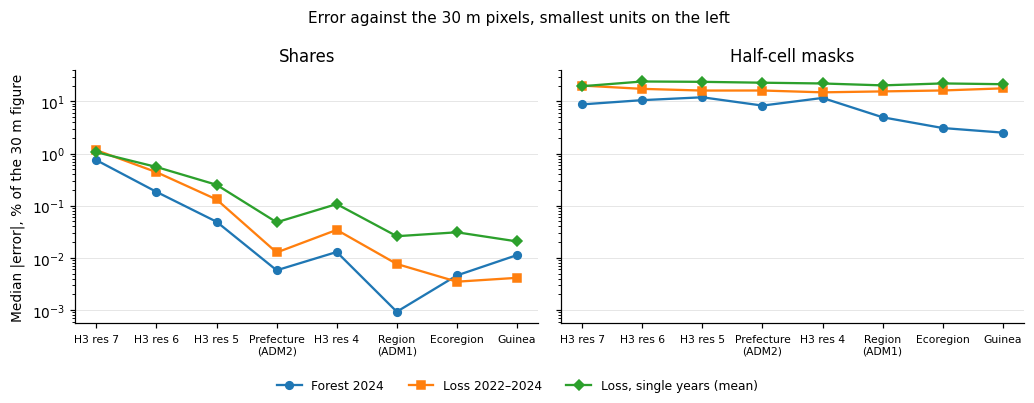

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
x = np.arange(len(ORDER))
for ax, method in zip(axes, ("Shares", "Half-cell masks")):
    v = view(method, "Median |error| (%)")
    for figure, marker in zip(["Forest 2024", "Loss 2022–2024", "Loss, single years (mean)"], "osD"):
        ax.plot(x, v[figure].values, marker=marker, lw=1.5, ms=5, label=figure)
    ax.set_yscale("log")
    ax.set_xticks(x, [NAMES.get(l, l).replace(" (", "\n(") for l in ORDER], rotation=0, fontsize=7)
    ax.set_title(method)
    ax.grid(axis="y", lw=0.4, alpha=0.5)
axes[0].set_ylabel("Median |error|, % of the 30 m figure")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False, fontsize=8)
fig.suptitle("Error against the 30 m pixels, smallest units on the left", fontsize=10)
fig.tight_layout(rect=(0, 0.07, 1, 1))

**Reading:**

* **The half-cell masks miss even the national figures:**
  * forest in 2024: −2.5 % (5.74 against 5.89 million ha, 148,000 ha short);
  * loss over 2001–2024: +4.7 %;
  * loss over 2022–2024: +17.8 %;
  * single years: 21 % off on average.
* **Per unit it is worse:**
  * median error of the 2024 forest: 3–12 %, and 11–65 % at the 95th percentile;
  * median error of the 2022–2024 loss: 15–20 %.
  * A cell just under half forest counts as none, and one just over as all; across a small unit these do not cancel.
* **Four platform products count these masks:**
  * the forest-cover layer and its hexagons;
  * the forest under the hexagon risk;
  * the prefecture risk summary's forest area;
  * the baseline projection's forest.
* **Each can read the shares instead,** as the zonal tables already do. For risk, the scored forest of a unit is the sum of its cells' forest shares.

## 3 · Units that do not cover Guinea, and the fix

The national figure counts every cell inside Guinea's outline (ADM0). The regions, prefectures and ecoregions come from other polygons, so their sum can fall short of it. The fix tested here: a cell inside Guinea but outside every polygon goes to the nearest unit (and so does each 30 m pixel in it, for the reference).

In [5]:
national = levels["ADM0"][2].iloc[0]
rows = {}
for l in ("ADM1", "ADM2", "ecoregion"):
    for label, key in (("Polygons only (platform)", l), ("Border cells to the nearest unit", l + "+nearest")):
        rows[(NAMES[l], label)] = 100 * (1 - levels[key][2].sum() / national)
gap = pd.DataFrame(rows).T[["Land", "Forest 2000", "Forest 2024", "Loss 2001–2024"]]
print("Share of Guinea's 30 m figure outside every unit (%)")
display(gap.round(2).abs())

rows = []
for l in ("ADM1", "ADM2", "ecoregion"):
    before, after = levels[l][2], levels[l + "+nearest"][2]
    change = 100 * (after["Forest 2024"] / before["Forest 2024"] - 1)
    e = R.errors(levels[l + "+nearest"][0], after).loc[["Forest 2024", "Loss 2022–2024"]]
    names_l = R.units(l).set_index("unit")["name"]
    rows.append({"Level": NAMES[l], "Units": len(after),
                 "Forest 2024 added, median (%)": change.median(), "Forest 2024 added, largest (%)": change.max(),
                 "Largest change in": names_l[change.idxmax()],
                 "Shares against 30 m, forest 2024, median |error| (%)": e.loc["Forest 2024", "Median |error| (%)"],
                 "Shares against 30 m, loss 2022–2024, median |error| (%)": e.loc["Loss 2022–2024", "Median |error| (%)"]})
print("With border cells to the nearest unit")
pd.DataFrame(rows).set_index("Level").round(3)

Share of Guinea's 30 m figure outside every unit (%)


Land  Forest 2000  \
Region (ADM1)     Polygons only (platform)          0.53         0.38   
                  Border cells to the nearest unit  0.00         0.00   
Prefecture (ADM2) Polygons only (platform)          0.53         0.38   
                  Border cells to the nearest unit  0.00         0.00   
Ecoregion         Polygons only (platform)          1.10         0.85   
                  Border cells to the nearest unit  0.00         0.00   

                                                    Forest 2024  \
Region (ADM1)     Polygons only (platform)                 0.40   
                  Border cells to the nearest unit         0.00   
Prefecture (ADM2) Polygons only (platform)                 0.40   
                  Border cells to the nearest unit         0.00   
Ecoregion         Polygons only (platform)                 0.92   
                  Border cells to the nearest unit         0.00   

                                                    Loss 2001–2024  
Region (ADM1)     Polygons only (platform)                    0.35  
                  Border cells to the nearest unit            0.00  
Prefecture (ADM2) Polygons only (platform)                    0.35  
                  Border cells to the nearest unit            0.00  
Ecoregion         Polygons only (platform)                    0.64  
                  Border cells to the nearest unit            0.00

With border cells to the nearest unit


,Units,"Forest 2024 added, median (%)","Forest 2024 added, largest (%)",Largest change in,"Shares against 30 m, forest 2024, median |error| (%)","Shares against 30 m, loss 2022–2024, median |error| (%)"
Level,,,,,,
Region (ADM1),8,0.231,3.819,Conakry,0.001,0.004
Prefecture (ADM2),34,0.047,3.819,Conakry,0.007,0.013
Ecoregion,5,1.620,8.555,Guinean mangroves,0.005,0.003


**Reading:**

* **geoBoundaries' ADM1 and ADM2 polygons leave 0.5 % of Guinea's land outside every unit.** That is 0.4 % of its forest and 0.35 % of its loss, in 146,000 cells along the border (median 0.35 km from it). The polygons are drawn coarser than the national outline. The RESOLVE ecoregions leave 1.1 % of the land outside.
* **So the platform's regional and prefecture tables add up to 99.6 % of the national figure.**
* **Giving each border cell to the nearest unit closes the gap exactly** at every level, at 100 m and at 30 m.
  * Regions and prefectures gain a median 0.23 % and 0.05 % of their forest, at most 3.8 %. Ecoregions gain a median 1.6 %, at most 8.6 % (the unit is named in the table).
  * The shares stay within 0.01 % of the 30 m figures (median).
* **The tables below use this assignment.**

## 4 · The tables

From the shares, with border cells to the nearest unit, per unit: land, forest in 2000 and 2024, loss over 2001–2024 and 2022–2024, and the loss rate of 2022–2024 (% of the forest of 2021 per year), with the 30 m figure beside the forest of 2024 and the recent loss. Regions, prefectures and ecoregions are in `outputs/summary/02_areas_*.csv`; hexagons, resolutions 4 to 7 with every year, in `data/reports/areas_h3_res*.parquet` (not committed).

In [6]:
def area_table(shares, truth):
    t = pd.DataFrame({"Land (ha)": shares["Land"], "Forest 2000 (ha)": shares["Forest 2000"],
                      "Forest 2024 (ha)": shares["Forest 2024"], "Forest 2024, 30 m (ha)": truth["Forest 2024"],
                      "Loss 2001–2024 (ha)": shares["Loss 2001–2024"], "Loss 2022–2024 (ha)": shares["Loss 2022–2024"],
                      "Loss 2022–2024, 30 m (ha)": truth["Loss 2022–2024"]})
    t["Loss rate 2022–2024 (%/yr)"] = 100 * shares["Loss 2022–2024"] / 3 / (shares["Forest 2024"] + shares["Loss 2022–2024"])
    return t

names = {l: R.units(l).set_index("unit")["name"] for l in ("ADM1", "ADM2", "ecoregion")}
for level in ("ADM1", "ADM2", "ecoregion"):
    shares, _, truth = levels[level + "+nearest"]
    table = area_table(shares, truth)
    table.insert(0, "Name", names[level].reindex(table.index).values)
    table.round(1).to_csv(OUT / f"02_areas_{level}.csv")
(R.DATA).mkdir(parents=True, exist_ok=True)
for res in range(4, 8):
    shares, _, truth = levels[f"H3 res {res}"]
    shares.round(2).to_parquet(R.DATA / f"areas_h3_res{res}.parquet")
adm1 = pd.read_csv(OUT / "02_areas_ADM1.csv", index_col=0).set_index("Name").sort_values("Loss 2022–2024 (ha)", ascending=False)
adm1.round(0).assign(**{"Loss rate 2022–2024 (%/yr)": adm1["Loss rate 2022–2024 (%/yr)"].round(2)})

,Land (ha),Forest 2000 (ha),Forest 2024 (ha),"Forest 2024, 30 m (ha)",Loss 2001–2024 (ha),Loss 2022–2024 (ha),"Loss 2022–2024, 30 m (ha)",Loss rate 2022–2024 (%/yr)
Name,,,,,,,,
Nzerekore,3662429.0,2303766.0,1699644.0,1699626.0,604122.0,115275.0,115284.0,2.1
Kindia,2555772.0,1126779.0,563117.0,563174.0,563662.0,82264.0,82261.0,4.2
Boke,3404343.0,942585.0,592482.0,593123.0,350103.0,60908.0,60909.0,3.1
Mamou,1783380.0,875678.0,573324.0,573320.0,302354.0,58888.0,58889.0,3.1
Faranah,3583407.0,1486169.0,1260327.0,1260310.0,225842.0,55178.0,55184.0,1.4
Kankan,7221009.0,1204786.0,1033663.0,1033657.0,171123.0,44369.0,44374.0,1.4
Labe,2292398.0,238369.0,155969.0,155971.0,82399.0,15827.0,15826.0,3.1
Conakry,39610.0,7426.0,7362.0,7370.0,64.0,16.0,16.0,0.1


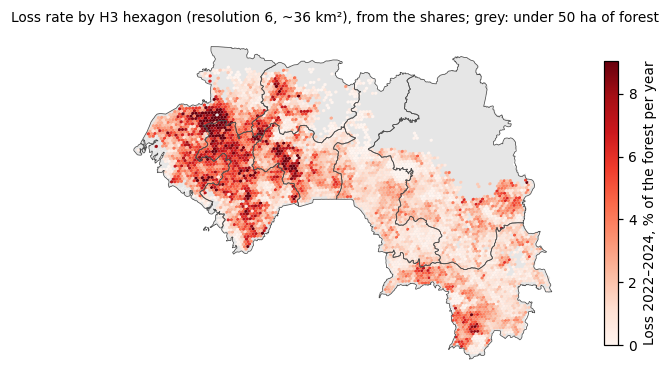

In [7]:
import geopandas as gpd
import h3
from shapely.geometry import Polygon
shares, _, _ = levels["H3 res 6"]
rate = 100 * shares["Loss 2022–2024"] / 3 / (shares["Forest 2024"] + shares["Loss 2022–2024"])
rate = rate[(shares["Forest 2024"] + shares["Loss 2022–2024"]) >= 50]
hexes = gpd.GeoDataFrame({"rate": rate.values}, crs=4326,
                         geometry=[Polygon([(lon, lat) for lat, lon in h3.cell_to_boundary(h)]) for h in rate.index])
adm1_lines = gpd.read_file(R.ADM / "geoBoundaries-GIN-ADM1.geojson")
fig, ax = plt.subplots(figsize=(7, 5.6))
gpd.GeoSeries([R.G.outline()], crs=4326).plot(ax=ax, color="0.9", linewidth=0)
hexes.plot(column="rate", ax=ax, cmap="Reds", vmin=0, vmax=np.nanpercentile(rate, 98), linewidth=0,
           legend=True, legend_kwds={"label": "Loss 2022–2024, % of the forest per year", "shrink": 0.6})
adm1_lines.boundary.plot(ax=ax, color="0.3", lw=0.5)
ax.set_axis_off()
ax.set_title("Loss rate by H3 hexagon (resolution 6, ~36 km²), from the shares; grey: under 50 ha of forest", fontsize=9);

## 5 · What this means

* **The shares are right at every reporting level the platform uses:**
  * Guinea, regions, prefectures and ecoregions within 0.01 % (median);
  * H3 hexagons within about 1 % at resolution 7 and under 0.6 % at resolution 6.
  * The platform's national summary and zonal tables, which already count the shares, need no change.
* **For the team to implement on the platform** (also in the README, "Decisions for the team"):
  * **Count forest from the shares, not the half-cell masks,** in four products: the forest-cover layer and its hexagons, the forest under the hexagon risk, the prefecture risk summary, and the baseline projection. The masks put Guinea's 2024 forest 2.5 % low and are 3–12 % off per unit (median).
  * **Give the cells along the border that fall outside every ADM1/ADM2 polygon to the nearest unit** (section 3). Tested: the regional tables then add up to the national figure exactly (now 0.4 % short), and the shares stay within 0.01 % of the 30 m figures.
* **Tables for reporting:**
  * regions, prefectures and ecoregions: `outputs/summary/02_areas_*.csv`;
  * hexagons, resolutions 4–7: `data/reports/`.